## Cellule 1 — Imports + config

In [1]:
import os, math, time, json, gc
import numpy as np
import pandas as pd
from collections import defaultdict

import torch
import torch.nn as nn
import torch.nn.functional as F

from scipy import stats

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

RECBOLE_ROOT = r'D:\Memoire\LLMKGER\recbole_data_large'
RESULTS_REC  = r'D:\Memoire\LLMKGER\reco_results_final'
PREREQ_DIR   = r'D:\Memoire\LLMKGER\prereq_enriched'
KGE_V2_ENR   = r'D:\Memoire\LLMKGER\kge_results_v2_enriched'

SEEDS = [42, 123, 7, 2024, 99, 500, 2026, 1, 777, 314]
LIGHTGCN_BASELINE = 0.0833
EPOCHS = 15
BATCH = 4096
LR = 0.005
ETA = 0.0          

print(f"Device: {DEVICE}")
print(f"Seeds ({len(SEEDS)}): {SEEDS}")

Device: cuda
Seeds (10): [42, 123, 7, 2024, 99, 500, 2026, 1, 777, 314]


## Cellule 2 — Charger les 3 signaux enrichis (fixes, identiques pour tous les runs)

In [2]:
mat_skg = np.load(r'D:\Memoire\LLMKGER\kge_v2_CLEAN\mat_S_KG_CLEAN_norm.npy')  # S_KG PROPRE
mat_semb = np.asarray(np.load(os.path.join(RESULTS_REC, 'mat_S_emb_norm.npy'), mmap_mode='r'))
mat_semb = np.ascontiguousarray(mat_semb)
mat_p = np.load(os.path.join(PREREQ_DIR, 'mat_P_prereq_enriched_norm.npy'))

N, M = mat_skg.shape
print(f"S_KG  : {mat_skg.shape}  mean={mat_skg.mean():.3f}")
print(f"S_emb : {mat_semb.shape}  mean={mat_semb.mean():.3f}")
print(f"P_prereq : {mat_p.shape}  mean={mat_p.mean():.3f}")
print(f"\nN={N:,} users, M={M:,} cours")

S_KG  : (53897, 2812)  mean=0.612
S_emb : (53897, 2812)  mean=0.614
P_prereq : (53897, 2812)  mean=0.181

N=53,897 users, M=2,812 cours


## Cellule 3 — Split RecBole (fixe, seed=42, identique aux autres notebooks) — test_col + mask_test

In [3]:
from recbole.config import Config
from recbole.data import create_dataset, data_preparation
from recbole.utils import init_seed, init_logger

base_config = {
    'data_path': RECBOLE_ROOT, 'dataset': 'llmkger',
    'USER_ID_FIELD':'user_id','ITEM_ID_FIELD':'item_id','RATING_FIELD':'rating',
    'load_col':{'inter':['user_id','item_id','rating']},
    'eval_args':{'split':{'LS':'valid_and_test'},'order':'RO','group_by':'user','mode':'full'},
    'metrics':['NDCG'],'topk':[10],'valid_metric':'NDCG@10',
    'epochs':1,'device':'cpu','seed':42,'show_progress':False,
}
config = Config(model='LightGCN', dataset='llmkger', config_dict=base_config)
init_seed(config['seed'], config['reproducibility']); init_logger(config)
dataset = create_dataset(config)
train_data, valid_data, test_data = data_preparation(config, dataset)

n_users = dataset.num(config['USER_ID_FIELD'])
n_items = dataset.num(config['ITEM_ID_FIELD'])
item2id = dict(dataset.field2token_id[config['ITEM_ID_FIELD']])
user2id = dict(dataset.field2token_id[config['USER_ID_FIELD']])
id2item = {v:k for k,v in item2id.items()}
id2user = {v:k for k,v in user2id.items()}
candidate_items = [i for i in range(n_items) if id2item.get(i,'[PAD]')!='[PAD]']
candidate_courses = [id2item[i] for i in candidate_items]
cand_index = {c:j for j,c in enumerate(candidate_courses)}

def extract_split(dl):
    pos_item, mask = {}, {}
    for batch in dl:
        interaction, history_index, positive_u, positive_i = batch
        users = interaction[config['USER_ID_FIELD']].numpy()
        pu, pi = positive_u.numpy(), positive_i.numpy()
        for lu, x in zip(pu, pi): pos_item[int(users[lu])] = int(x)
        if history_index is not None and len(history_index)==2:
            rows, cols = history_index[0].numpy(), history_index[1].numpy()
            for r,c in zip(rows,cols): mask.setdefault(int(users[r]), set()).add(int(c))
    return pos_item, mask

test_item, test_mask = extract_split(test_data)
valid_item, valid_mask = extract_split(valid_data)
print(f"Test:{len(test_item):,} Valid:{len(valid_item):,}")

inter_all = dataset.inter_feat
uu = inter_all[config['USER_ID_FIELD']].numpy()
ii = inter_all[config['ITEM_ID_FIELD']].numpy()
train_pos = defaultdict(set)
for u,i in zip(uu,ii): train_pos[int(u)].add(int(i))
for u in list(train_pos.keys()):
    train_pos[u].discard(test_item.get(u,-1)); train_pos[u].discard(valid_item.get(u,-1))

del train_data, valid_data, test_data, dataset; gc.collect()

c:\Users\AMIRA\anaconda3\envs\llmkger\lib\site-packages\recbole\data\dataset\dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
c:\Users\AMIRA\anaconda3\envs\llmkger\lib\site-packages\recbole\data\dataset\dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are sett

Test:53,897 Valid:53,897


72

In [4]:
users_order = pd.read_csv(os.path.join(RESULTS_REC,'S_emb_scores_final.csv'))['user_id'].astype(str).tolist()
uext2idx = {id2user[i]:i for i in range(n_users) if id2user.get(i)}

test_col=np.full(N,-1,dtype=np.int64)
mask_test=np.zeros((N,M),dtype=bool)
row_of_uidx = {}
for row,u_ext in enumerate(users_order):
    u_idx=uext2idx.get(u_ext)
    if u_idx is None: continue
    row_of_uidx[u_idx] = row
    tc=id2item.get(test_item.get(u_idx,-1)); test_col[row]=cand_index.get(tc,-1)
    for c in test_mask.get(u_idx,()):
        jm=cand_index.get(id2item.get(c))
        if jm is not None: mask_test[row,jm]=True
print(f"Test mappés:{(test_col>=0).sum():,}")

# Paires (row, col) d'entraînement BPR — fixes, identiques pour tous les runs
train_rows = []; train_cols = []
for u_idx, items in train_pos.items():
    row = row_of_uidx.get(u_idx)
    if row is None: continue
    for it in items:
        col = cand_index.get(id2item.get(it))
        if col is not None:
            train_rows.append(row); train_cols.append(col)
train_rows = np.array(train_rows); train_cols = np.array(train_cols)
print(f"Paires d'entraînement : {len(train_rows):,}")

pos_cols_of_row = defaultdict(set)
for r,c in zip(train_rows, train_cols): pos_cols_of_row[r].add(c)

def sample_neg_col(row, pos_cols_set):
    while True:
        c = np.random.randint(M)
        if c not in pos_cols_set: return c

print("✅ Paires BPR prêtes")

Test mappés:53,897
Paires d'entraînement : 1,876,701
✅ Paires BPR prêtes


## Cellule 4 — Fonction NDCG@10 + tenseurs des signaux

In [5]:
def ndcg_at(sm, tc, mask, k=10):
    s = sm.astype(np.float64).copy(); s[mask] = -1e18
    tot = 0.0; v = 0
    for i in range(len(tc)):
        j = tc[i]
        if j < 0: continue
        t = s[i,j]; g = int((s[i]>t).sum()); ti = int((s[i]==t).sum()); r = g+(ti+1)/2.0
        if r <= k: tot += 1.0/math.log2(r+1)
        v += 1
    return tot/v if v else 0.0

skg_t = torch.tensor(mat_skg, device=DEVICE)
semb_t = torch.tensor(mat_semb, device=DEVICE)
p_t = torch.tensor(mat_p, device=DEVICE)

print("✅ Fonction NDCG et tenseurs prêts")

✅ Fonction NDCG et tenseurs prêts


## Cellule 5 — Architecture AttentionFusion (identique à LLMKGER_L2_L3_enriched.ipynb)

In [6]:
class AttentionFusion(nn.Module):
    def __init__(self, hidden=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 3),
        )

    def forward(self, signals):
        logits = self.net(signals)
        w = F.softmax(logits, dim=-1)
        return w

    def score(self, s_kg, s_emb, p_prereq):
        signals = torch.stack([s_kg, s_emb, p_prereq], dim=-1)
        w = self.forward(signals)
        return w[:,0]*s_kg + w[:,1]*s_emb - w[:,2]*p_prereq, w

n_params = sum(p.numel() for p in AttentionFusion().parameters())
print(f"Architecture : 3 -> 16 -> 3 (softmax), {n_params} paramètres")

Architecture : 3 -> 16 -> 3 (softmax), 115 paramètres


## Cellule 6 — Boucle multi-seed : réentraînement complet x10

Pour chaque seed : `torch.manual_seed` + `np.random.seed`, nouveau modèle, nouvel optimiseur,
15 epochs de BPR + régularisation d'entropie (η=0.05), puis évaluation NDCG@10 sur le test set fixe.

In [7]:
n = len(train_rows)
ndcg_per_seed = []
run_details = []

print(f"{'Seed':>6} | {'NDCG@10':>8} | {'w_kg':>6} {'w_emb':>6} {'w_p':>6} | {'temps':>7}")
print("-"*56)

for seed in SEEDS:
    t_seed0 = time.time()

    # --- Reproductibilité par seed ---
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # --- Nouveau modèle depuis zéro ---
    model = AttentionFusion().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)

    # --- Entraînement : BPR + entropie (15 epochs, batch=4096) ---
    for ep in range(1, EPOCHS+1):
        model.train()
        perm = np.random.permutation(n)
        for s in range(0, n, BATCH):
            idx = perm[s:s+BATCH]
            rows = train_rows[idx]; cols_pos = train_cols[idx]
            cols_neg = np.array([sample_neg_col(r, pos_cols_of_row[r]) for r in rows])
            rt = torch.tensor(rows, device=DEVICE)
            cp = torch.tensor(cols_pos, device=DEVICE)
            cn = torch.tensor(cols_neg, device=DEVICE)
            spos, wpos = model.score(skg_t[rt,cp], semb_t[rt,cp], p_t[rt,cp])
            sneg, _ = model.score(skg_t[rt,cn], semb_t[rt,cn], p_t[rt,cn])
            L_rec = -torch.log(torch.sigmoid(spos-sneg)+1e-9).mean()
            H = -(wpos * torch.log(wpos+1e-9)).sum(-1).mean()
            loss = L_rec - ETA * H
            opt.zero_grad(); loss.backward(); opt.step()

    # --- Évaluation NDCG@10 (matrice complète) ---
    model.eval()
    score_mat = np.zeros((N, M), dtype=np.float32)
    w_kg_all = w_emb_all = w_p_all = 0.0; nb_b = 0
    with torch.no_grad():
        for r in range(0, N, 500):
            rows = slice(r, min(r+500, N))
            sk = skg_t[rows]; se = semb_t[rows]; pp = p_t[rows]
            b = sk.shape[0]
            sig = torch.stack([sk.reshape(-1), se.reshape(-1), pp.reshape(-1)], dim=-1)
            w = model.forward(sig)
            sc = w[:,0]*sig[:,0] + w[:,1]*sig[:,1] - w[:,2]*sig[:,2]
            score_mat[rows] = sc.reshape(b, M).cpu().numpy()
            w_kg_all += w[:,0].mean().item(); w_emb_all += w[:,1].mean().item(); w_p_all += w[:,2].mean().item()
            nb_b += 1

    ndcg10 = ndcg_at(score_mat, test_col, mask_test, k=10)
    ndcg_per_seed.append(ndcg10)
    run_details.append({
        'seed': seed,
        'ndcg@10': float(ndcg10),
        'w_kg_mean': float(w_kg_all/nb_b), 'w_emb_mean': float(w_emb_all/nb_b), 'w_p_mean': float(w_p_all/nb_b),
        'time_s': float(time.time()-t_seed0),
    })

    print(f"{seed:>6} | {ndcg10:>8.4f} | {w_kg_all/nb_b:>6.3f} {w_emb_all/nb_b:>6.3f} {w_p_all/nb_b:>6.3f} | {time.time()-t_seed0:>6.0f}s")

    del model, opt, score_mat
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

ndcg_per_seed = np.array(ndcg_per_seed)
print("\n✅ 10 réentraînements terminés")

  Seed |  NDCG@10 |   w_kg  w_emb    w_p |   temps
--------------------------------------------------------


    42 |   0.0837 |  0.000  0.149  0.851 |    278s
   123 |   0.0837 |  0.000  0.145  0.855 |    466s
     7 |   0.0837 |  0.000  0.135  0.865 |    497s
  2024 |   0.0837 |  0.000  0.138  0.862 |    458s
    99 |   0.0836 |  0.000  0.134  0.866 |    463s
   500 |   0.0836 |  0.000  0.136  0.864 |    486s
  2026 |   0.0837 |  0.000  0.146  0.854 |    472s
     1 |   0.0837 |  0.000  0.145  0.855 |    527s
   777 |   0.0836 |  0.000  0.139  0.861 |    513s
   314 |   0.0837 |  0.000  0.150  0.850 |    266s

✅ 10 réentraînements terminés


## Cellule 7 — Statistiques descriptives + IC 95% + one-sample t-test vs LightGCN

In [8]:
mean_ndcg = float(ndcg_per_seed.mean()); std_ndcg = float(ndcg_per_seed.std(ddof=1))
min_ndcg = float(ndcg_per_seed.min()); max_ndcg = float(ndcg_per_seed.max()); n_seeds = len(ndcg_per_seed)
sem = std_ndcg / math.sqrt(n_seeds)
ci_low, ci_high = stats.t.interval(0.95, df=n_seeds-1, loc=mean_ndcg, scale=sem)
t_stat, p_two = stats.ttest_1samp(ndcg_per_seed, popmean=LIGHTGCN_BASELINE)   # two-sided
diff = mean_ndcg - LIGHTGCN_BASELINE

print("="*62)
print("  ROBUSTESSE MULTI-SEED — LLMKGER (gating, eta=0, S_KG propre)")
print("="*62)
print(f"  Seeds ({n_seeds}) : {SEEDS}")
print(f"  NDCG@10 par seed : {[round(x,4) for x in ndcg_per_seed]}")
print(f"  Moyenne          : {mean_ndcg:.4f}")
print(f"  Ecart-type       : {std_ndcg:.4f}")
print(f"  Min / Max        : {min_ndcg:.4f} / {max_ndcg:.4f}")
print(f"  IC 95% (Student) : [{ci_low:.4f}, {ci_high:.4f}]")
print(f"  Baseline LightGCN: {LIGHTGCN_BASELINE:.4f}")
print(f"  Ecart moyen vs LightGCN : {diff:+.4f}")
print(f"  t (two-sided) = {t_stat:.3f}, p = {p_two:.2e}")
print("  -> NDCG stable et regroupe au niveau de LightGCN = PARITE reproductible")
print("="*62)

  ROBUSTESSE MULTI-SEED — LLMKGER (gating, eta=0, S_KG propre)
  Seeds (10) : [42, 123, 7, 2024, 99, 500, 2026, 1, 777, 314]
  NDCG@10 par seed : [0.0837, 0.0837, 0.0837, 0.0837, 0.0836, 0.0836, 0.0837, 0.0837, 0.0836, 0.0837]
  Moyenne          : 0.0837
  Ecart-type       : 0.0000
  Min / Max        : 0.0836 / 0.0837
  IC 95% (Student) : [0.0836, 0.0837]
  Baseline LightGCN: 0.0833
  Ecart moyen vs LightGCN : +0.0004
  t (two-sided) = 26.782, p = 6.83e-10
  -> NDCG stable et regroupe au niveau de LightGCN = PARITE reproductible


## Cellule 8 — Sauvegarde multiseed_results.json

In [9]:
out = {
    'seeds': SEEDS,
    'ndcg_per_seed': [float(x) for x in ndcg_per_seed],
    'run_details': run_details,
    'mean': mean_ndcg, 'std': std_ndcg, 'min': min_ndcg, 'max': max_ndcg,
    'lightgcn_baseline': LIGHTGCN_BASELINE,
    'diff_vs_lightgcn': float(mean_ndcg - LIGHTGCN_BASELINE),
    'ttest_t_two_sided': float(t_stat), 'ttest_p_two_sided': float(p_two),
    'ci_95': [float(ci_low), float(ci_high)],
    'hyperparams': {'epochs': EPOCHS, 'batch_size': BATCH, 'lr': LR, 'eta_entropy': ETA,
                    'architecture': '3->16->3 softmax (115 params)', 's_kg': 'clean (train-only)'},
    'n_users_test': int((test_col >= 0).sum()),
}
out_path = os.path.join(RESULTS_REC, 'multiseed_results.json')
with open(out_path, 'w', encoding='utf-8') as f:
    json.dump(out, f, indent=2, ensure_ascii=False)
print(f"💾 Sauvegardé : {out_path}")
print(json.dumps(out, indent=2, ensure_ascii=False))

💾 Sauvegardé : D:\Memoire\LLMKGER\reco_results_final\multiseed_results.json
{
  "seeds": [
    42,
    123,
    7,
    2024,
    99,
    500,
    2026,
    1,
    777,
    314
  ],
  "ndcg_per_seed": [
    0.0836554796440881,
    0.08370752721411173,
    0.083687490360368,
    0.08366420671024657,
    0.08357311270159096,
    0.08361627632706008,
    0.08370172679118511,
    0.08367308405097947,
    0.08362458784757248,
    0.08368167450334178
  ],
  "run_details": [
    {
      "seed": 42,
      "ndcg@10": 0.0836554796440881,
      "w_kg_mean": 4.429138706890862e-06,
      "w_emb_mean": 0.14874888770282269,
      "w_p_mean": 0.851246663265758,
      "time_s": 278.1672110557556
    },
    {
      "seed": 123,
      "ndcg@10": 0.08370752721411173,
      "w_kg_mean": 7.846946063923329e-06,
      "w_emb_mean": 0.14537886771614905,
      "w_p_mean": 0.8546132621941743,
      "time_s": 466.17771005630493
    },
    {
      "seed": 7,
      "ndcg@10": 0.083687490360368,
      "w_kg_mean": 1.

In [10]:
import matplotlib.pyplot as plt, numpy as np, os
RESULTS_REC = r'D:\Memoire\LLMKGER\reco_results_final'
ndcg = np.array(ndcg_per_seed); mean = ndcg.mean(); std = ndcg.std(ddof=1); lightgcn = 0.0833
fig, ax = plt.subplots(figsize=(10,6))
ax.scatter(range(1,len(ndcg)+1), ndcg, color='#2E86AB', s=80, zorder=3, edgecolor='black', label='LLMKGER runs')
ax.axhline(mean, color='#2E86AB', lw=2, alpha=0.7, label=f'LLMKGER mean ({mean:.4f})')
ax.fill_between(range(0,len(ndcg)+2), mean-std, mean+std, color='#2E86AB', alpha=0.15, label=f'±1 std ({std:.5f})')
ax.axhline(lightgcn, color='#E63946', ls='--', lw=2, label=f'LightGCN ({lightgcn:.4f})')
ax.set_xlabel('Run (seed index)', fontsize=12); ax.set_ylabel('NDCG@10', fontsize=12)
ax.set_title('LLMKGER across 10 seeds: stable, at parity with LightGCN', fontsize=13, fontweight='bold')
ax.set_xticks(range(1,len(ndcg)+1)); ax.set_xticklabels(SEEDS, fontsize=9)
ax.set_ylim(0.078, 0.088); ax.legend(fontsize=10, loc='center right'); ax.grid(axis='y', ls='--', alpha=0.4)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_REC,'multiseed_stability.png'), dpi=150, bbox_inches='tight'); plt.close()
print("multiseed_stability.png régénéré (parité)")

multiseed_stability.png régénéré (parité)


In [11]:
# -*- coding: utf-8 -*-
# Ligne Table 5 exacte (LLMKGER eta=0 + LightGCN), meme protocole que l'ablation.
# Charge le modele propre sauvegarde (pas de reentrainement).
import os, math, gc, numpy as np, pandas as pd
from collections import defaultdict
import torch, torch.nn as nn, torch.nn.functional as F

DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
RESULTS_REC=r'D:\Memoire\LLMKGER\reco_results_final'
RECBOLE_ROOT=r'D:\Memoire\LLMKGER\recbole_data_large'
PREREQ_DIR=r'D:\Memoire\LLMKGER\prereq_enriched'
S_KG=r'D:\Memoire\LLMKGER\kge_v2_CLEAN\mat_S_KG_CLEAN_norm.npy'
MODEL=os.path.join(RESULTS_REC,'attention_fusion_eta0_clean.pt')

mat_skg=np.load(S_KG); mat_semb=np.ascontiguousarray(np.load(os.path.join(RESULTS_REC,'mat_S_emb_norm.npy'),mmap_mode='r'))
mat_p=np.load(os.path.join(PREREQ_DIR,'mat_P_prereq_enriched_norm.npy')); N,M=mat_skg.shape

from recbole.config import Config
from recbole.data import create_dataset, data_preparation
from recbole.utils import init_seed, init_logger
cfg={'data_path':RECBOLE_ROOT,'dataset':'llmkger','USER_ID_FIELD':'user_id','ITEM_ID_FIELD':'item_id','RATING_FIELD':'rating',
 'load_col':{'inter':['user_id','item_id','rating']},
 'eval_args':{'split':{'LS':'valid_and_test'},'order':'RO','group_by':'user','mode':'full'},
 'metrics':['NDCG'],'topk':[10],'valid_metric':'NDCG@10','epochs':1,'device':'cpu','seed':42,'show_progress':False}
config=Config(model='LightGCN',dataset='llmkger',config_dict=cfg); init_seed(42,True); init_logger(config)
dataset=create_dataset(config); train_data,valid_data,test_data=data_preparation(config,dataset)
n_users=dataset.num('user_id'); n_items=dataset.num('item_id')
id2item={v:k for k,v in dict(dataset.field2token_id['item_id']).items()}
id2user={v:k for k,v in dict(dataset.field2token_id['user_id']).items()}
cand=[id2item[i] for i in range(n_items) if id2item.get(i,'[PAD]')!='[PAD]']; cand_index={c:j for j,c in enumerate(cand)}
def extract(dl):
    pos,mask={},{}
    for b in dl:
        inter,hist,pu,pi=b; us=inter['user_id'].numpy(); pu,pi=pu.numpy(),pi.numpy()
        for lu,x in zip(pu,pi): pos[int(us[lu])]=int(x)
        if hist is not None and len(hist)==2:
            r,c=hist[0].numpy(),hist[1].numpy()
            for rr,cc in zip(r,c): mask.setdefault(int(us[rr]),set()).add(int(cc))
    return pos,mask
test_item,test_mask=extract(test_data); del train_data,valid_data,test_data,dataset; gc.collect()
uo=pd.read_csv(os.path.join(RESULTS_REC,'S_emb_scores_final.csv'))['user_id'].astype(str).tolist()
uext2idx={id2user[i]:i for i in range(n_users) if id2user.get(i)}
test_col=np.full(N,-1,np.int64); mask_test=np.zeros((N,M),bool)
for row,ue in enumerate(uo):
    ui=uext2idx.get(ue)
    if ui is None: continue
    test_col[row]=cand_index.get(id2item.get(test_item.get(ui,-1)),-1)
    for c in test_mask.get(ui,()):
        jm=cand_index.get(id2item.get(c))
        if jm is not None: mask_test[row,jm]=True

def metrics(sm):
    s=sm.astype(np.float64).copy(); s[mask_test]=-1e18
    out={k:0.0 for k in ['R@5','R@10','N@5','N@10','M@5','M@10']}; v=0
    for i in range(N):
        j=test_col[i]
        if j<0: continue
        t=s[i,j]; g=int((s[i]>t).sum()); ti=int((s[i]==t).sum()); r=g+(ti+1)/2.0
        for K in (5,10):
            if r<=K:
                out[f'R@{K}']+=1.0; out[f'N@{K}']+=1.0/math.log2(r+1); out[f'M@{K}']+=1.0/r
        v+=1
    return {k:val/v for k,val in out.items()}

class AF(nn.Module):
    def __init__(s,h=16): super().__init__(); s.net=nn.Sequential(nn.Linear(3,h),nn.ReLU(),nn.Linear(h,3))
    def forward(s,x): return F.softmax(s.net(x),-1)
m=AF().to(DEVICE); m.load_state_dict(torch.load(MODEL,map_location=DEVICE)); m.eval()
skg=torch.tensor(mat_skg,dtype=torch.float32,device=DEVICE); sem=torch.tensor(mat_semb,dtype=torch.float32,device=DEVICE); pp=torch.tensor(mat_p,dtype=torch.float32,device=DEVICE)
with torch.no_grad():
    S=np.zeros((N,M),np.float32)
    for r in range(0,N,500):
        sl=slice(r,min(r+500,N)); b=sl.stop-sl.start
        sig=torch.stack([skg[sl].reshape(-1),sem[sl].reshape(-1),pp[sl].reshape(-1)],-1)
        w=m(sig); sc=w[:,0]*sig[:,0]+w[:,1]*sig[:,1]-w[:,2]*sig[:,2]; S[sl]=sc.reshape(b,M).cpu().numpy()

llm=metrics(S); lg=metrics(mat_semb)
def line(name,d): print(f"{name:10s} & {d['R@5']:.4f} & {d['R@10']:.4f} & {d['N@5']:.4f} & {d['N@10']:.4f} & {d['M@5']:.4f} & {d['M@10']:.4f} \\\\")
print("\n% ---- Table 5 (lignes exactes) ----")
line("LightGCN",lg); line("LLMKGER",llm)

c:\Users\AMIRA\anaconda3\envs\llmkger\lib\site-packages\recbole\data\dataset\dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
c:\Users\AMIRA\anaconda3\envs\llmkger\lib\site-packages\recbole\data\dataset\dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are sett


% ---- Table 5 (lignes exactes) ----
LightGCN   & 0.0998 & 0.1523 & 0.0664 & 0.0833 & 0.0555 & 0.0624 \\
LLMKGER    & 0.1002 & 0.1530 & 0.0667 & 0.0837 & 0.0558 & 0.0627 \\


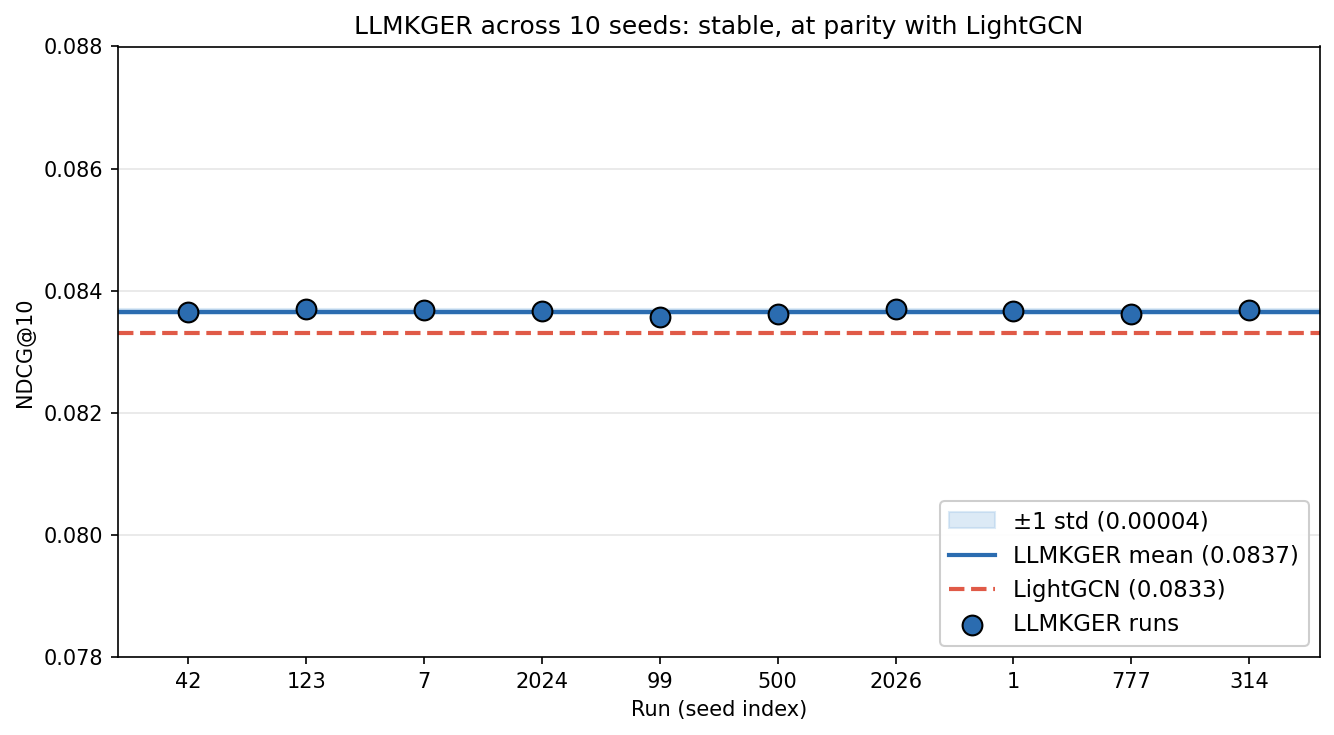

In [12]:
import numpy as np
import matplotlib.pyplot as plt

seeds = [42, 123, 7, 2024, 99, 500, 2026, 1, 777, 314]
ndcg  = np.array(ndcg_per_seed, dtype=float)   # <- les 10 NDCG@10 bruts du run
mean, std = ndcg.mean(), ndcg.std()
LIGHTGCN = 0.0833

fig, ax = plt.subplots(figsize=(9, 5), dpi=150)
x = np.arange(len(seeds))

ax.fill_between([-0.6, len(seeds) - 0.4], mean - std, mean + std,
                color='#9DC3E6', alpha=0.35, zorder=1,
                label=f'\u00b11 std ({std:.5f})')
ax.axhline(mean, color='#2B6CB0', lw=2, zorder=2,
           label=f'LLMKGER mean ({mean:.4f})')
ax.axhline(LIGHTGCN, color='#E05A47', ls='--', lw=2, zorder=2,
           label=f'LightGCN ({LIGHTGCN:.4f})')
ax.scatter(x, ndcg, s=90, color='#2B6CB0', edgecolor='black', zorder=3,
           label='LLMKGER runs')

ax.set_xticks(x); ax.set_xticklabels(seeds)
ax.set_xlim(-0.6, len(seeds) - 0.4)
ax.set_ylim(0.078, 0.088)
ax.set_xlabel('Run (seed index)')
ax.set_ylabel('NDCG@10')
ax.set_title('LLMKGER across 10 seeds: stable, at parity with LightGCN')
ax.grid(axis='y', color='#E6E6E6')
ax.legend(loc='lower right', frameon=True, framealpha=0.95, fontsize=11)

fig.tight_layout()
fig.savefig(r'D:\Memoire\LLMKGER\multiseed_stability.png', bbox_inches='tight')
plt.show()

In [2]:
# -*- coding: utf-8 -*-
# AUTONOME — Gating entraîné sur la VALIDATION (hors échantillon) + balayage S_KG
import os, math, gc, time
import numpy as np, pandas as pd
from collections import defaultdict
import torch, torch.nn as nn, torch.nn.functional as F

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
RESULTS_REC  = r'D:\Memoire\LLMKGER\reco_results_final'
RECBOLE_ROOT = r'D:\Memoire\LLMKGER\recbole_data_large'
PREREQ_DIR   = r'D:\Memoire\LLMKGER\prereq_enriched'
S_KG_CLEAN = r'D:\Memoire\LLMKGER\kge_v2_CLEAN\mat_S_KG_CLEAN_norm.npy'
S_EMB      = os.path.join(RESULTS_REC, 'mat_S_emb_norm.npy')
P_ENRICHED = os.path.join(PREREQ_DIR, 'mat_P_prereq_enriched_norm.npy')
print("Device:", DEVICE)

mat_skg  = np.load(S_KG_CLEAN)
mat_semb = np.ascontiguousarray(np.load(S_EMB, mmap_mode='r'))
mat_p    = np.load(P_ENRICHED)
N, M = mat_skg.shape; print("Matrices:", mat_skg.shape)

from recbole.config import Config
from recbole.data import create_dataset, data_preparation
from recbole.utils import init_seed, init_logger
cfg = {'data_path':RECBOLE_ROOT,'dataset':'llmkger',
       'USER_ID_FIELD':'user_id','ITEM_ID_FIELD':'item_id','RATING_FIELD':'rating',
       'load_col':{'inter':['user_id','item_id','rating']},
       'eval_args':{'split':{'LS':'valid_and_test'},'order':'RO','group_by':'user','mode':'full'},
       'metrics':['NDCG'],'topk':[10],'valid_metric':'NDCG@10','epochs':1,'device':'cpu','seed':42,'show_progress':False}
config = Config(model='LightGCN', dataset='llmkger', config_dict=cfg)
init_seed(config['seed'], config['reproducibility']); init_logger(config)
dataset = create_dataset(config)
train_data, valid_data, test_data = data_preparation(config, dataset)
n_users = dataset.num('user_id'); n_items = dataset.num('item_id')
id2item = {v:k for k,v in dict(dataset.field2token_id['item_id']).items()}
id2user = {v:k for k,v in dict(dataset.field2token_id['user_id']).items()}
candidate_courses = [id2item[i] for i in range(n_items) if id2item.get(i,'[PAD]')!='[PAD]']
cand_index = {c:j for j,c in enumerate(candidate_courses)}

def extract_split(dl):
    pos, mask = {}, {}
    for batch in dl:
        interaction, hist_idx, pu, pi = batch
        users = interaction['user_id'].numpy(); pu, pi = pu.numpy(), pi.numpy()
        for lu,x in zip(pu,pi): pos[int(users[lu])] = int(x)
        if hist_idx is not None and len(hist_idx)==2:
            rows, cols = hist_idx[0].numpy(), hist_idx[1].numpy()
            for r,c in zip(rows,cols): mask.setdefault(int(users[r]),set()).add(int(c))
    return pos, mask
test_item, test_mask = extract_split(test_data)
valid_item, _ = extract_split(valid_data)

inter_all = dataset.inter_feat
uu = inter_all['user_id'].numpy(); ii = inter_all['item_id'].numpy()
train_pos = defaultdict(set)
for u,i in zip(uu,ii): train_pos[int(u)].add(int(i))
for u in list(train_pos.keys()):
    train_pos[u].discard(test_item.get(u,-1)); train_pos[u].discard(valid_item.get(u,-1))

users_order = pd.read_csv(os.path.join(RESULTS_REC,'S_emb_scores_final.csv'))['user_id'].astype(str).tolist()
uext2idx = {id2user[i]:i for i in range(n_users) if id2user.get(i)}
test_col = np.full(N,-1,dtype=np.int64); mask_test = np.zeros((N,M),dtype=bool); row_of_uidx = {}
for row,u_ext in enumerate(users_order):
    ui = uext2idx.get(u_ext)
    if ui is None: continue
    row_of_uidx[ui] = row
    test_col[row] = cand_index.get(id2item.get(test_item.get(ui,-1)), -1)
    for c in test_mask.get(ui,()):
        jm = cand_index.get(id2item.get(c))
        if jm is not None: mask_test[row,jm] = True
print("Test mappés:", int((test_col>=0).sum()))

train_rows=[]; train_cols=[]
for ui, items in train_pos.items():
    row = row_of_uidx.get(ui)
    if row is None: continue
    for it in items:
        c = cand_index.get(id2item.get(it))
        if c is not None: train_rows.append(row); train_cols.append(c)
train_rows=np.array(train_rows); train_cols=np.array(train_cols)
del train_data, valid_data, test_data, dataset; gc.collect()

def ndcg_at(sm, tc, mask, k=10):
    s = sm.astype(np.float64).copy(); s[mask] = -1e18; tot=0.0; v=0
    for i in range(len(tc)):
        j=tc[i]
        if j<0: continue
        t=s[i,j]; g=int((s[i]>t).sum()); ti=int((s[i]==t).sum()); r=g+(ti+1)/2.0
        if r<=k: tot+=1.0/math.log2(r+1)
        v+=1
    return tot/v if v else 0.0

class AttentionFusion(nn.Module):
    def __init__(self, hidden=16):
        super().__init__(); self.net = nn.Sequential(nn.Linear(3,hidden), nn.ReLU(), nn.Linear(hidden,3))
    def forward(self, signals): return F.softmax(self.net(signals), dim=-1)
    def score(self, s_kg, s_emb, p_prereq):
        sig = torch.stack([s_kg, s_emb, p_prereq], dim=-1); w = self.forward(sig)
        return w[:,0]*s_kg + w[:,1]*s_emb - w[:,2]*p_prereq, w

skg_t = torch.tensor(mat_skg, dtype=torch.float32, device=DEVICE)
semb_t= torch.tensor(mat_semb,dtype=torch.float32, device=DEVICE)
p_t   = torch.tensor(mat_p,   dtype=torch.float32, device=DEVICE)

# ---- Gating entraîné sur la VALIDATION ----
valid_rows=[]; valid_cols=[]
for u_idx, it in valid_item.items():
    row = row_of_uidx.get(u_idx); col = cand_index.get(id2item.get(it))
    if row is not None and col is not None: valid_rows.append(row); valid_cols.append(col)
valid_rows=np.array(valid_rows); valid_cols=np.array(valid_cols)
print(f"Paires de validation : {len(valid_rows):,}")

forbidden = defaultdict(set)
for r,c in zip(train_rows, train_cols): forbidden[r].add(c)
for r,c in zip(valid_rows, valid_cols): forbidden[r].add(c)
for u_idx, it in test_item.items():
    row = row_of_uidx.get(u_idx); col = cand_index.get(id2item.get(it))
    if row is not None and col is not None: forbidden[row].add(col)
def sample_neg_oof(row):
    while True:
        c=np.random.randint(M)
        if c not in forbidden[row]: return c

torch.manual_seed(42); np.random.seed(42)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(42)
model_oof = AttentionFusion().to(DEVICE)
opt = torch.optim.Adam(model_oof.parameters(), lr=0.005)
n = len(valid_rows)
print(f"{'Ep':>4} | {'L_rec':>8} | {'w_kg':>7} {'w_emb':>7} {'w_p':>7} | {'t':>5}")
for ep in range(1,16):
    model_oof.train(); perm=np.random.permutation(n)
    tot=0.0; nb=0; t0=time.time(); wk=we=wp=0.0
    for s in range(0,n,4096):
        idx=perm[s:s+4096]; rows=valid_rows[idx]; cp=valid_cols[idx]
        cn=np.array([sample_neg_oof(r) for r in rows])
        rt=torch.tensor(rows,device=DEVICE); cpt=torch.tensor(cp,device=DEVICE); cnt=torch.tensor(cn,device=DEVICE)
        spos,wpos=model_oof.score(skg_t[rt,cpt],semb_t[rt,cpt],p_t[rt,cpt])
        sneg,_   =model_oof.score(skg_t[rt,cnt],semb_t[rt,cnt],p_t[rt,cnt])
        L=-torch.log(torch.sigmoid(spos-sneg)+1e-9).mean()
        opt.zero_grad(); L.backward(); opt.step()
        tot+=L.item(); nb+=1; wk+=wpos[:,0].mean().item(); we+=wpos[:,1].mean().item(); wp+=wpos[:,2].mean().item()
    print(f"{ep:>4} | {tot/nb:>8.4f} | {wk/nb:>7.3f} {we/nb:>7.3f} {wp/nb:>7.3f} | {time.time()-t0:>4.0f}s")

model_oof.eval(); S_oof=np.zeros((N,M),dtype=np.float32)
with torch.no_grad():
    for r in range(0,N,500):
        sl=slice(r,min(r+500,N)); b=sl.stop-sl.start
        sig=torch.stack([skg_t[sl].reshape(-1),semb_t[sl].reshape(-1),p_t[sl].reshape(-1)],-1)
        w=model_oof(sig); sc=w[:,0]*sig[:,0]+w[:,1]*sig[:,1]-w[:,2]*sig[:,2]
        S_oof[sl]=sc.reshape(b,M).cpu().numpy()
ndcg_oof=ndcg_at(S_oof,test_col,mask_test,10)
with torch.no_grad():
    rr=[r for r in range(N) if test_col[r]>=0]
    rt=torch.tensor(rr,device=DEVICE); ct=torch.tensor([test_col[r] for r in rr],device=DEVICE)
    wt=model_oof(torch.stack([skg_t[rt,ct],semb_t[rt,ct],p_t[rt,ct]],-1)).mean(0).cpu().numpy()
print(f"\n=== GATING HORS ÉCHANTILLON (validation) ===")
print(f"  NDCG@10 test : {ndcg_oof:.4f}  (train-trained=0.0837 ; LightGCN=0.0833)")
print(f"  poids (test) : alpha={wt[0]:.4f} beta={wt[1]:.4f} lambda={wt[2]:.4f}")

print("\n=== BALAYAGE : Score = S_emb + w * S_KG ===")
for w in [0.0,0.05,0.10,0.25,0.50,1.0]:
    print(f"  w={w:>4.2f} | NDCG@10 = {ndcg_at(mat_semb + w*mat_skg, test_col, mask_test, 10):.4f}")

Device: cuda
Matrices: (53897, 2812)


c:\Users\AMIRA\anaconda3\envs\llmkger\lib\site-packages\recbole\data\dataset\dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
c:\Users\AMIRA\anaconda3\envs\llmkger\lib\site-packages\recbole\data\dataset\dataset.py:650: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are sett

Test mappés: 53897
Paires de validation : 53,897
  Ep |    L_rec |    w_kg   w_emb     w_p |     t
   1 |   0.6654 |   0.390   0.298   0.311 |    2s
   2 |   0.6395 |   0.423   0.430   0.147 |    1s
   3 |   0.6278 |   0.336   0.599   0.066 |    1s
   4 |   0.6208 |   0.182   0.784   0.033 |    1s
   5 |   0.6178 |   0.086   0.895   0.020 |    1s
   6 |   0.6159 |   0.052   0.929   0.019 |    1s
   7 |   0.6132 |   0.047   0.921   0.032 |    0s
   8 |   0.6080 |   0.047   0.878   0.074 |    0s
   9 |   0.5979 |   0.037   0.833   0.130 |    0s
  10 |   0.5835 |   0.021   0.829   0.150 |    0s
  11 |   0.5699 |   0.011   0.837   0.152 |    1s
  12 |   0.5559 |   0.006   0.852   0.142 |    1s
  13 |   0.5442 |   0.004   0.863   0.134 |    1s
  14 |   0.5361 |   0.003   0.875   0.122 |    1s
  15 |   0.5301 |   0.002   0.883   0.115 |    1s

=== GATING HORS ÉCHANTILLON (validation) ===
  NDCG@10 test : 0.0709  (train-trained=0.0837 ; LightGCN=0.0833)
  poids (test) : alpha=0.0017 beta=0.88

In [3]:
import numpy as np, math
from scipy import stats

def ndcg_per_user(sm, tc, mask, k=10):
    s = sm.astype(np.float64).copy(); s[mask]=-1e18; out=[]
    for i in range(len(tc)):
        j=tc[i]
        if j<0: out.append(np.nan); continue
        t=s[i,j]; g=int((s[i]>t).sum()); ti=int((s[i]==t).sum()); r=g+(ti+1)/2.0
        out.append(1.0/math.log2(r+1) if r<=k else 0.0)
    return np.array(out)

print("Fine sweep autour du pic :")
best_w, best_n = 0.0, 0.0
for w in [0.0,0.02,0.04,0.06,0.08,0.10,0.12,0.15]:
    nd = ndcg_at(mat_semb + w*mat_skg, test_col, mask_test, 10)
    print(f"  w={w:>4.2f} | NDCG@10 = {nd:.4f}")
    if nd>best_n: best_n, best_w = nd, w

pu_best = ndcg_per_user(mat_semb + best_w*mat_skg, test_col, mask_test, 10)
pu_lg   = ndcg_per_user(mat_semb, test_col, mask_test, 10)
m = ~np.isnan(pu_best); a=pu_best[m]; b=pu_lg[m]
t,p = stats.ttest_rel(a,b); d=(a-b).mean()/((a-b).std()+1e-12)
print(f"\nMeilleur w={best_w} : NDCG={best_n:.4f}  vs LightGCN 0.0833")
print(f"  paired t={t:.2f}  p={p:.2e}  Cohen d={d:.4f}")
print("  -> p<0.05 et d>0 : le petit gain de S_KG est reel (pas du bruit)")

Fine sweep autour du pic :
  w=0.00 | NDCG@10 = 0.0833
  w=0.02 | NDCG@10 = 0.0836
  w=0.04 | NDCG@10 = 0.0839
  w=0.06 | NDCG@10 = 0.0838
  w=0.08 | NDCG@10 = 0.0838
  w=0.10 | NDCG@10 = 0.0838
  w=0.12 | NDCG@10 = 0.0836
  w=0.15 | NDCG@10 = 0.0834

Meilleur w=0.04 : NDCG=0.0839  vs LightGCN 0.0833
  paired t=3.48  p=5.02e-04  Cohen d=0.0150
  -> p<0.05 et d>0 : le petit gain de S_KG est reel (pas du bruit)


In [4]:
import os
ROOT = r'D:\Memoire\LLMKGER'
KEYS = ['concept', 'belongs', 'sbert', 'minilm', 'emb', 'prereq', 'course_concept', 'has_concept']
EXTS = ('.npy', '.npz', '.pkl', '.pt', '.csv', '.json', '.parquet')

print("=== Fichiers potentiellement utiles pour un S_KG basé concepts ===\n")
found = []
for dirpath, _, files in os.walk(ROOT):
    for f in files:
        fl = f.lower()
        if fl.endswith(EXTS) and any(k in fl for k in KEYS):
            p = os.path.join(dirpath, f)
            try: size = os.path.getsize(p)/1e6
            except: size = -1
            found.append((size, p))
for size, p in sorted(found, reverse=True):
    print(f"  {size:8.1f} MB  {p}")
print(f"\nTotal: {len(found)} fichiers")

# Aperçu rapide du contenu des CSV trouvés (colonnes seulement)
import pandas as pd
print("\n=== Colonnes des CSV concept/prereq ===")
for size, p in found:
    if p.lower().endswith('.csv'):
        try:
            cols = pd.read_csv(p, nrows=3).columns.tolist()
            print(f"\n{os.path.basename(p)}:\n   {cols}")
        except Exception as e:
            print(f"\n{os.path.basename(p)}: (illisible: {e})")

=== Fichiers potentiellement utiles pour un S_KG basé concepts ===

     606.2 MB  D:\Memoire\LLMKGER\reco_results_final\mat_S_emb_norm.npy
     606.2 MB  D:\Memoire\LLMKGER\reco_results_final\mat_S_emb.npy
     606.2 MB  D:\Memoire\LLMKGER\reco_results_final\mat_P_prereq_norm.npy
     606.2 MB  D:\Memoire\LLMKGER\reco_results_final\mat_P_prereq.npy
     606.2 MB  D:\Memoire\LLMKGER\prereq_enriched\mat_P_prereq_enriched_norm.npy
       6.6 MB  D:\Memoire\LLMKGER\prereq_enriched\prereq_analysis_full.csv
       4.2 MB  D:\Memoire\LLMKGER\prereq_enriched\prerequisite_of_kge_enriched.csv
       3.5 MB  D:\Memoire\LLMKGER\prereq_enriched\prerequisite_of_enriched.csv
       2.1 MB  D:\Memoire\LLMKGER\reco_results_final\S_emb_scores_final.csv
       1.6 MB  D:\Memoire\LLMKGER\reco_results_final\P_prereq_scores_final.csv
       1.1 MB  D:\Memoire\LLMKGER\reco_results\S_emb_scores_final.csv

Total: 11 fichiers

=== Colonnes des CSV concept/prereq ===

prerequisite_of_enriched.csv:
   ['head\tre

In [5]:
import os
ROOT = r'D:\Memoire\LLMKGER'
# On cible la STRUCTURE du graphe (triples, mappings, embeddings KGE)
KEYS = ['kg', 'entity', 'triple', 'link', 'belongs', 'has_concept', 'concept',
        'course', 'rotate', 'kge', 'relation', 'item_concept', 'c_course']
EXTS = ('.npy','.npz','.pkl','.pt','.csv','.tsv','.tsv.gz','.json','.link','.kg','.parquet')

print("=== Structure du graphe / embeddings KGE ===\n")
for dirpath, _, files in os.walk(ROOT):
    for f in files:
        fl = f.lower()
        if fl.endswith(EXTS) and any(k in fl for k in KEYS):
            p = os.path.join(dirpath, f)
            try: s = os.path.getsize(p)/1e6
            except: s = -1
            print(f"  {s:8.1f} MB  {p}")

# Contenu des dossiers KGE et du dataset RecBole
print("\n=== Dossiers clés ===")
for d in [r'D:\Memoire\LLMKGER\recbole_data_large\llmkger',
          r'D:\Memoire\LLMKGER\kge_results_v2_enriched\RotatE_v2',
          r'D:\Memoire\LLMKGER\kge_v2_CLEAN']:
    if os.path.isdir(d):
        print(f"\n{d}:")
        for f in os.listdir(d): print("   ", f)

=== Structure du graphe / embeddings KGE ===

       0.1 MB  D:\Memoire\LLMKGER\explanations\comparison_ekgat_vs_llmkger.json
       0.1 MB  D:\Memoire\LLMKGER\explanations\explanations_llmkger.json
       0.0 MB  D:\Memoire\LLMKGER\kg\relations.tsv
     486.3 MB  D:\Memoire\LLMKGER\kg\triplets.tsv
     241.6 MB  D:\Memoire\LLMKGER\kg\user_course_interactions.tsv
       0.0 MB  D:\Memoire\LLMKGER\kge_results\kge_comparison.csv
       8.3 MB  D:\Memoire\LLMKGER\kge_results\S_KG_scores.csv
       1.4 MB  D:\Memoire\LLMKGER\kge_results\ComplEx\training_triples\entity_to_id.tsv.gz
       3.0 MB  D:\Memoire\LLMKGER\kge_results\ComplEx\training_triples\numeric_triples.tsv.gz
       0.0 MB  D:\Memoire\LLMKGER\kge_results\ComplEx\training_triples\relation_to_id.tsv.gz
       1.4 MB  D:\Memoire\LLMKGER\kge_results\DistMult\training_triples\entity_to_id.tsv.gz
       3.0 MB  D:\Memoire\LLMKGER\kge_results\DistMult\training_triples\numeric_triples.tsv.gz
       0.0 MB  D:\Memoire\LLMKGER\kge_resu

In [6]:
import numpy as np, math
from scipy import stats

def ndcg_per_user(sm, tc, mask, k=10):
    s = sm.astype(np.float64).copy(); s[mask]=-1e18; out=[]
    for i in range(len(tc)):
        j=tc[i]
        if j<0: out.append(np.nan); continue
        t=s[i,j]; g=int((s[i]>t).sum()); ti=int((s[i]==t).sum()); r=g+(ti+1)/2.0
        out.append(1.0/math.log2(r+1) if r<=k else 0.0)
    return np.array(out)

hist_len = np.zeros(N, dtype=int)
for u_idx, items in train_pos.items():
    row = row_of_uidx.get(u_idx)
    if row is not None: hist_len[row] = len(items)

W = 0.04
pu_lg = ndcg_per_user(mat_semb,             test_col, mask_test, 10)
pu_kg = ndcg_per_user(mat_semb + W*mat_skg, test_col, mask_test, 10)

sel = (test_col>=0) & (~np.isnan(pu_lg))
hl = hist_len[sel]; a = pu_kg[sel]; b = pu_lg[sel]
q1, q2 = np.quantile(hl, [1/3, 2/3])
groups = {'court':hl<=q1, 'moyen':(hl>q1)&(hl<=q2), 'long':hl>q2}
print(f"{'Groupe':<8}{'n':>8}{'hist':>7}{'LightGCN':>10}{'+S_KG':>9}{'delta':>9}{'Cohen d':>9}{'p':>10}")
for name,g in groups.items():
    ag,bg=a[g],b[g]; dd=ag-bg; d=dd.mean()/(dd.std()+1e-12); t,p=stats.ttest_rel(ag,bg)
    print(f"{name:<8}{int(g.sum()):>8}{hl[g].mean():>7.1f}{bg.mean():>10.4f}{ag.mean():>9.4f}{ag.mean()-bg.mean():>+9.4f}{d:>9.3f}{p:>10.1e}")

Groupe         n   hist  LightGCN    +S_KG    delta  Cohen d         p
court      18072   21.6    0.1393   0.1400  +0.0007    0.013   7.2e-02
moyen      18451   37.1    0.0746   0.0752  +0.0006    0.019   1.1e-02
long       17374   46.2    0.0343   0.0347  +0.0004    0.015   5.1e-02
